# Immuno Compass · Notebook 08: Model 2b, Bayesian **Beta-Binomial** regression (Day 10)

**Goal:** fix the over-confidence of the Binomial model by letting each cohort's true ADA rate **wobble** around what the
clues predict. Then check that the model can reproduce the real data (**posterior predictive check**) and that its
uncertainty ranges are honest on unseen drugs.

**Finish line:** clean sampling, a PPC, credible intervals, grouped-CV scores with coverage, and the final posterior
saved for the dashboard.

> 🧒 *Simple version:* the Binomial model says "every patient in a cohort flips the *same* coin". But cohorts differ in
> ways our clues don't capture (assay, population, the drug itself), so each cohort really has its **own slightly bent coin**.
> The Beta-Binomial says: "first pick a coin from a bag of coins centred on the prediction, then flip it n times".

### The model
$$\mu_i = \text{sigmoid}(\alpha + x_i\beta), \qquad p_i \sim \text{Beta}(\mu_i\phi,\ (1-\mu_i)\phi), \qquad y_i \sim \text{Binomial}(n_i, p_i)$$

* **Beta distribution:** a distribution *of probabilities* (between 0 and 1), with mean μ.
* **φ (phi), concentration:** large φ means the coins barely differ (back to Binomial); small φ means cohorts vary a lot.
* Equivalent view: patients in the same cohort are correlated with **ρ = 1 / (1 + φ)**, and the variance of y is inflated
  by **1 + (n − 1)ρ** compared with Binomial. So big cohorts no longer count as huge numbers of independent coin flips.
* Prior: φ ~ Exponential(0.1) (mean 10, allows anything from near-Binomial to very overdispersed).

> A per-drug random effect (the plan's optional extension 3) is **skipped**: it's first on the "cut if behind" list, and
> for *new* drugs it would add nothing to the point prediction. It's noted as future work.

In [1]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels pymc arviz

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [2]:
import warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pymc as pm, arviz as az, joblib
from scipy.stats import betabinom
np.random.seed(42)
for msg in ["Found unknown categories", ".*BLAS.*"]:
    warnings.filterwarnings("ignore", message=msg)
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("pymc").setLevel(logging.ERROR)

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped"]])
print(df.shape, "| drugs:", df[im.DRUG].nunique())

BLUE, ORANGE, AQUA, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

(1754, 39) | drugs: 137


## 1 · Fit on all cohorts and check the sampler

In [3]:
pre_bb, samples_bb, idata_bb = im.fit_bayes(df, kind="betabinomial")
summ = az.summary(idata_bb, var_names=["alpha", "beta", "phi"])
n_div = int(idata_bb.sample_stats.diverging.sum())
print(f"max r_hat = {summ.r_hat.max():.3f} | min bulk ESS = {summ.ess_bulk.min():.0f} | divergences = {n_div}")
assert summ.r_hat.max() <= 1.01 and n_div == 0, "sampler problems: do not trust these results"

phi = samples_bb["phi"]
rho = 1 / (1 + phi)
print(f"\nφ (concentration): {phi.mean():.2f}  [94 % interval {np.percentile(phi, 3):.2f}–{np.percentile(phi, 97):.2f}]")
print(f"ρ (within-cohort correlation): {rho.mean():.3f}")
for n_ in [10, 100, 1000]:
    print(f"  a cohort of {n_:>5} patients carries the information of only ≈ {n_ / (1 + (n_ - 1) * rho.mean()):.1f} independent patients")

max r_hat = 1.000 | min bulk ESS = 2854 | divergences = 0

φ (concentration): 3.59  [94 % interval 3.26–3.93]
ρ (within-cohort correlation): 0.218
  a cohort of    10 patients carries the information of only ≈ 3.4 independent patients
  a cohort of   100 patients carries the information of only ≈ 4.4 independent patients
  a cohort of  1000 patients carries the information of only ≈ 4.6 independent patients


**Reading φ:** the variance-inflation factor 1 + (n − 1)ρ means a 1,000-patient cohort is worth only a handful of
"independent" patients for learning about the *average* rate. This is exactly why the plain GLM, which treated it as
1,000, over-fitted to the biggest trials.

## 2 · Posterior predictive check (PPC): can the model reproduce the data?

We simulate **replicated datasets** from each fitted model (same cohorts, same n) and compare them with the real data.
A good model's fake data should look like the real data. For comparison we also refit the Binomial model.

In [4]:
pre_bin, samples_bin, _ = im.fit_bayes(df, kind="binomial")

def replicate(pre, samples, data, n_rep=200, seed=1):
    """Simulate n_rep replicated ADA frequencies per cohort from the posterior."""
    rng = np.random.default_rng(seed)
    mu, idx = im.bayes_mu_draws(pre, samples, data, max_draws=n_rep, seed=seed)
    if "phi" in samples:
        ph = samples["phi"][idx][:, None]
        p = rng.beta(np.clip(mu * ph, 1e-9, None), np.clip((1 - mu) * ph, 1e-9, None))
    else:
        p = mu
    return rng.binomial(data["n"].values, p) / data["n"].values      # (n_rep, cohorts)

rep_bin, rep_bb = replicate(pre_bin, samples_bin, df), replicate(pre_bb, samples_bb, df)
obs = df["ada_freq"].values

stats = {"share of cohorts at 0 %": lambda f: (f == 0).mean(),
         "share of cohorts above 50 %": lambda f: (f > 0.5).mean(),
         "SD of cohort ADA %": lambda f: f.std()}
rows = []
for name, fn in stats.items():
    rows.append({"statistic": name, "observed": fn(obs),
                 "Binomial (replicated, 94 % range)": f"{np.percentile([fn(r) for r in rep_bin], 3):.3f}–{np.percentile([fn(r) for r in rep_bin], 97):.3f}",
                 "Beta-Binomial (replicated, 94 % range)": f"{np.percentile([fn(r) for r in rep_bb], 3):.3f}–{np.percentile([fn(r) for r in rep_bb], 97):.3f}"})
display(pd.DataFrame(rows).style.format({"observed": "{:.3f}"}).hide(axis="index"))

statistic,observed,"Binomial (replicated, 94 % range)","Beta-Binomial (replicated, 94 % range)"
share of cohorts at 0 %,0.347,0.214–0.241,0.353–0.397
share of cohorts above 50 %,0.069,0.032–0.041,0.058–0.083
SD of cohort ADA %,0.205,0.161–0.171,0.192–0.213


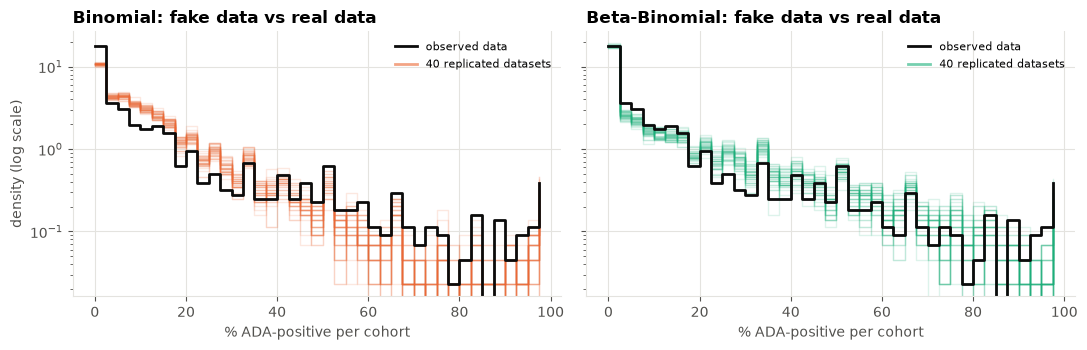

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, rep, name, color in [(axes[0], rep_bin, "Binomial", ORANGE), (axes[1], rep_bb, "Beta-Binomial", AQUA)]:
    for r in rep[:40]:
        h, _ = np.histogram(r, bins=bins, density=True)
        ax.step(bins[:-1] * 100, h, where="post", color=color, alpha=0.15, lw=1)
    h, _ = np.histogram(obs, bins=bins, density=True)
    ax.step(bins[:-1] * 100, h, where="post", color="#0b0b0b", lw=2, label="observed data")
    ax.plot([], [], color=color, lw=2, alpha=0.6, label="40 replicated datasets")
    ax.set_title(f"{name}: fake data vs real data"); ax.set_xlabel("% ADA-positive per cohort")
    ax.legend(frameon=False, fontsize=8); ax.set_yscale("log")
axes[0].set_ylabel("density (log scale)")
plt.tight_layout(); fig.savefig(ROOT / "figures" / "bayes_ppc.png"); plt.show()

## 3 · Posterior effects: honest credible intervals

Now that each big cohort counts for less, intervals widen to an honest size.

In [6]:
names = list(pre_bb.get_feature_names_out())
def post_table(samples):
    b = samples["beta"]
    t = pd.DataFrame({"OR_mean": np.exp(b).mean(0), "OR_3%": np.exp(np.percentile(b, 3, 0)),
                      "OR_97%": np.exp(np.percentile(b, 97, 0)), "P(effect > 0)": (b > 0).mean(0)}, index=names)
    t["excludes 1"] = (t["OR_3%"] > 1) | (t["OR_97%"] < 1)
    return t
post_bb, post_bin = post_table(samples_bb), post_table(samples_bin)
print(f"94 % credible intervals excluding OR = 1: Binomial {post_bin['excludes 1'].sum()} / 42 → Beta-Binomial {post_bb['excludes 1'].sum()} / 42")
print("(GLM with cluster-robust errors on Day 5: 11 / 42)")
display(post_bb.sort_values("OR_mean").style.format({"OR_mean": "{:.2f}", "OR_3%": "{:.2f}", "OR_97%": "{:.2f}", "P(effect > 0)": "{:.2f}"}))

94 % credible intervals excluding OR = 1: Binomial 39 / 42 → Beta-Binomial 18 / 42
(GLM with cluster-robust errors on Day 5: 11 / 42)


,OR_mean,OR_3%,OR_97%,P(effect > 0),excludes 1
modality_Antibody-drug conjugate,0.29,0.16,0.46,0.00,True
species_Other,0.36,0.08,0.97,0.03,True
indication_Healthy Volunteer,0.52,0.32,0.79,0.00,True
indication_Musculoskeletal,0.58,0.34,0.89,0.01,True
modality_Immunotoxin,0.70,0.23,1.54,0.16,False
backbone_Other,0.72,0.34,1.24,0.12,False
modality_Other,0.73,0.42,1.16,0.09,False
log_dose_mgkg,0.75,0.70,0.81,0.00,True
route_Ophthalmic,0.77,0.35,1.45,0.18,False
species_Human,0.78,0.66,0.90,0.00,True


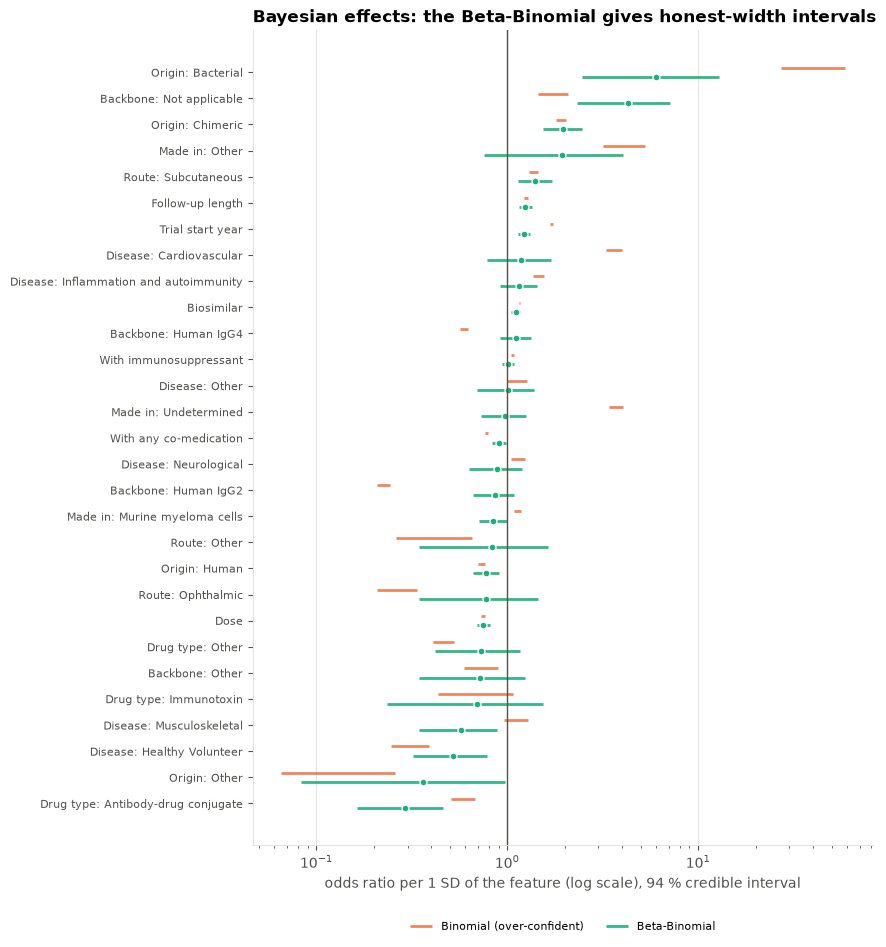

In [7]:
FEATURE_LABEL = {"route": "Route", "indication": "Disease", "modality": "Drug type", "species": "Origin",
                 "backbone": "Backbone", "expression": "Made in", "blinding": "Blinding", "randomized": "Randomised",
                 "comparator": "Comparator"}
SINGLE = {"log_dose_mgkg": "Dose", "start_year": "Trial start year", "log_followup_days": "Follow-up length",
          "co_immunosuppressant": "With immunosuppressant", "co_any_drug": "With any co-medication",
          "arm_mentions_placebo": "Arm mentions placebo", "biosimilar": "Biosimilar"}
def nice(col):
    if col in SINGLE: return SINGLE[col]
    if col.startswith("missingindicator_"): return col.replace("missingindicator_", "") + " missing"
    feat = next(c for c in im.CAT_FEATURES if col.startswith(c + "_"))
    return f"{FEATURE_LABEL[feat]}: {col[len(feat) + 1:]}"

DESIGN = ("blinding_", "randomized_", "comparator_", "missingindicator_", "arm_mentions_placebo")
f = post_bb.loc[[n for n in names if not n.startswith(DESIGN)]].sort_values("OR_mean")
fb = post_bin.loc[f.index]
fig, ax = plt.subplots(figsize=(8, 0.32 * len(f) + 1.3))
yy = np.arange(len(f))
ax.hlines(yy + 0.18, fb["OR_3%"], fb["OR_97%"], color=ORANGE, lw=2, alpha=0.8, label="Binomial (over-confident)")
ax.hlines(yy - 0.18, f["OR_3%"], f["OR_97%"], color=AQUA, lw=2, alpha=0.9, label="Beta-Binomial")
ax.plot(f["OR_mean"], yy - 0.18, "o", color=AQUA, ms=5, mec="white", mew=1)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yticks(yy, [nice(c) for c in f.index], fontsize=8)
ax.set_xlabel("odds ratio per 1 SD of the feature (log scale), 94 % credible interval")
ax.set_title("Bayesian effects: the Beta-Binomial gives honest-width intervals"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.06 - 0.6 / len(f)), ncol=2)
fig.savefig(ROOT / "figures" / "bayes_forest.png"); plt.show()

## 4 · Grouped CV: unseen drugs

In [8]:
pred_rows = []
def bayes_bb(train, test):
    pre, samples, idata = im.fit_bayes(train, kind="betabinomial")
    s = az.summary(idata, var_names=["alpha", "beta", "phi"])
    print(f"  fold fit: max r_hat {s.r_hat.max():.3f}, divergences {int(idata.sample_stats.diverging.sum())}, φ ≈ {samples['phi'].mean():.2f}")
    pr = im.bayes_predictive(pre, samples, test)
    pred_rows.append(pd.DataFrame({"cohort_id": test["cohort_id"].values, "lps": pr["lps"], "lo": pr["lo"], "hi": pr["hi"]}))
    return im.predict_bayes(pre, samples, test)

pf, oof = im.cross_validate(df, "fold_grouped", bayes_bb)
im.save_results("bayes_betabinomial", pf, oof, df, ROOT)
pred_bb = pd.concat(pred_rows).set_index("cohort_id").loc[df["cohort_id"]].reset_index()
pred_bb.to_csv(ROOT / "results" / "predictive_bayes_betabinomial.csv", index=False)
print("\nBeta-Binomial, grouped CV:", {k: round(v, 4) for k, v in pf.drop(columns="fold").mean().items()})

  fold fit: max r_hat 1.000, divergences 0, φ ≈ 3.17


  fold fit: max r_hat 1.000, divergences 0, φ ≈ 3.43


  fold fit: max r_hat 1.000, divergences 0, φ ≈ 4.07


  fold fit: max r_hat 1.000, divergences 0, φ ≈ 4.04


  fold fit: max r_hat 1.000, divergences 0, φ ≈ 5.08



Beta-Binomial, grouped CV: {'wMAE': 0.1697, 'wRMSE': 0.2138, 'loglik': -22.1296}


In [9]:
pred_bin = pd.read_csv(ROOT / "results" / "predictive_bayes_binomial.csv")
y = df["y"].values
rows = []
for name, pr in [("Bayesian Binomial", pred_bin), ("Bayesian Beta-Binomial", pred_bb)]:
    inside = (y >= pr["lo"].values) & (y <= pr["hi"].values)
    rows.append({"model": name, "log predictive score ↑": pr["lps"].mean(), "90 % interval coverage (target 90 %)": inside.mean(),
                 "coverage, cohorts n ≥ 100": inside[df["n"].values >= 100].mean()})
display(pd.DataFrame(rows).style.format({"log predictive score ↑": "{:.2f}", "90 % interval coverage (target 90 %)": "{:.1%}",
                                         "coverage, cohorts n ≥ 100": "{:.1%}"}).hide(axis="index"))

keys = ["naive", "glm_l2", "xgb_default", "bayes_binomial", "bayes_betabinomial"]
cv = pd.concat([pd.read_csv(ROOT / "results" / f"cv_{k}.csv") for k in keys])
display(cv.groupby("model")[["wMAE", "wRMSE", "loglik"]].agg(["mean", "std"]).reindex(keys).style.format("{:.3f}"))

model,log predictive score ↑,90 % interval coverage (target 90 %),"coverage, cohorts n ≥ 100"
Bayesian Binomial,-30.77,48.6%,18.8%
Bayesian Beta-Binomial,-2.97,87.6%,81.7%


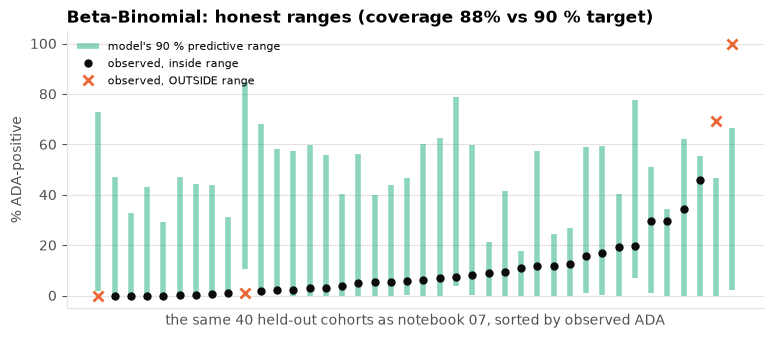

In [10]:
inside = (y >= pred_bb["lo"].values) & (y <= pred_bb["hi"].values)
s = df.assign(lo=pred_bb["lo"].values / df["n"].values, hi=pred_bb["hi"].values / df["n"].values, inside=inside)
s = s[s["n"] >= 50].sample(40, random_state=3).sort_values("ada_freq").reset_index(drop=True)   # same cohorts as notebook 07
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.vlines(s.index, s["lo"] * 100, s["hi"] * 100, color=AQUA, lw=4, alpha=0.5, label="model's 90 % predictive range")
ax.plot(s.index[s.inside], s.loc[s.inside, "ada_freq"] * 100, "o", color="#0b0b0b", ms=5, label="observed, inside range")
ax.plot(s.index[~s.inside], s.loc[~s.inside, "ada_freq"] * 100, "x", color=ORANGE, ms=7, mew=2, label="observed, OUTSIDE range")
ax.set_xticks([]); ax.set_xlabel("the same 40 held-out cohorts as notebook 07, sorted by observed ADA")
ax.set_ylabel("% ADA-positive"); ax.set_title(f"Beta-Binomial: honest ranges (coverage {inside.mean():.0%} vs 90 % target)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(ROOT / "figures" / "bayes_betabinomial_coverage.png"); plt.show()

## 5 · Save the final posterior for the dashboard

We store the fitted preprocessor and 1,000 posterior draws. The dashboard computes predictions and credible ranges
from these draws, so it applies **exactly** the training preprocessing.

In [11]:
rng = np.random.default_rng(0)
keep = rng.choice(len(samples_bb["alpha"]), size=1000, replace=False)
export = {"preprocessor": pre_bb, "alpha": samples_bb["alpha"][keep], "beta": samples_bb["beta"][keep],
          "phi": samples_bb["phi"][keep], "features": im.ALL_FEATURES, "columns": names}
joblib.dump(export, ROOT / "models" / "bayes_betabinomial.joblib")
check = joblib.load(ROOT / "models" / "bayes_betabinomial.joblib")
assert np.allclose(im.predict_bayes(check["preprocessor"], check, df.head(10)).round(6),
                   im.predict_bayes(pre_bb, {k: check[k] for k in ["alpha", "beta", "phi"]}, df.head(10)).round(6))
print("saved models/bayes_betabinomial.joblib ✔ (1,000 draws)")

saved models/bayes_betabinomial.joblib ✔ (1,000 draws)


## 6 · Day 10 findings (write-up)

1. **Very strong overdispersion, now quantified.** φ ≈ **3.6** [3.3–3.9], so patients within a cohort are correlated with ρ ≈ 0.22. A cohort of 1,000 patients carries about as much information about the *average* ADA rate as ≈ 5 independent patients. This is why the Binomial models over-fitted giant trials.
2. **The model reproduces the data (posterior predictive check).** Observed: 34.7 % of cohorts at 0 %, 6.9 % above 50 %, SD 0.205. Beta-Binomial replicates: 35–40 %, 6–8 %, 0.19–0.21, all matching. Binomial replicates: only 21–24 % zeros, 3–4 % above 50 %, SD 0.16–0.17, so it **fails** the check.
3. **Honest uncertainty on unseen drugs.** The 90 % predictive ranges contain **87.6 %** of held-out cohorts (Binomial: 48.6 %), and **81.7 %** of cohorts with n ≥ 100 (Binomial: 18.8 %). The log predictive score improves from −30.8 to **−3.0**. The sampler was clean in every fold (r̂ = 1.00, 0 divergences).
4. **Effects with 94 % credible intervals excluding OR = 1** (per 1 SD): 18 of 42, down from 39 of 42 under Binomial (cluster-robust GLM: 11). Among the clearest:
   * **higher ADA:** bacterial origin (OR 6.0 [2.5–12.8]), non-antibody backbone (4.3), active-controlled trials (2.3), **chimeric vs humanized (2.0 [1.5–2.5])**, **subcutaneous vs IV (1.40 [1.14–1.71])**, longer follow-up (1.24), later start year (1.22)
   * **lower ADA:** antibody-drug conjugates (0.29 [0.16–0.46]), healthy volunteers (0.52), fully human vs humanized (0.78 [0.66–0.90]), higher dose (0.75 [0.70–0.81])
   * Compared with the GLM, the Beta-Binomial's down-weighting of giant trials makes the **"foreignness" gradient (human < humanized < chimeric < bacterial) and the subcutaneous-route effect clearer**, matching the biology.
   * Caveat: this model allows cohort-level variation but **not drug-level clustering** (no per-drug random effect), so these intervals are probably still somewhat narrow. The cluster-robust GLM (11/42) is the conservative reference.
5. **Point accuracy (n-weighted) is not better than the naive baseline:** wMAE 0.170 vs 0.137. This is expected. The Beta-Binomial gives each cohort roughly equal say (each ≈ 3–5 effective patients), while wMAE is dominated by the largest cohorts. It is the right model for **honest uncertainty and effect estimation**, not for matching big-trial averages. Notebook 10 compares predictive *distributions* fairly, including an intercept-only Beta-Binomial baseline.

The final posterior (1,000 draws + preprocessor) is saved as `models/bayes_betabinomial.joblib` for the dashboard.